<a href="https://colab.research.google.com/github/ruqayaahabib/Advanced-AI-Labs/blob/main/Week-05/Ruqaya_Lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("hour.csv")
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
# First 10 rows
display(df.head(10))

# Shape
print("Shape:", df.shape)

# Columns
print("Columns:", df.columns.tolist())

# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Descriptive statistics
display(df.describe())

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


Shape: (17379, 17)
Columns: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
Missing Values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [ ]:
X = df.drop(columns=["cnt", "casual", "registered", "instant", "dteday"])
y = df["cnt"]

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Target: cnt


In [ ]:
# Rush hour: 7-9 AM and 4-6 PM
X["is_rush_hour"] = X["hr"].isin([7, 8, 9, 16, 17, 18]).astype(int)

# Weekend: Sunday = 0, Saturday = 6
X["is_weekend"] = X["weekday"].isin([0, 6]).astype(int)

# Temperature and humidity interaction
X["temp_humidity_interaction"] = X["temp"] * X["hum"]

# Good weather: clear or partly cloudy
X["good_weather"] = (X["weathersit"] == 1).astype(int)

display(X.head())

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,is_rush_hour,is_weekend,temp_humidity_interaction,good_weather
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,0,1,0.1944,1
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,0,1,0.1760,1
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,0,1,0.1760,1
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,0.1800,1
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,0.1800,1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (13903, 16)
Testing: (3476, 16)


In [ ]:
categorical_features = [
    "season", "yr", "mnth", "hr",
    "holiday", "weekday", "workingday",
    "weathersit", "is_rush_hour",
    "is_weekend", "good_weather"
]

numerical_features = [
    "temp", "atemp", "hum", "windspeed",
    "temp_humidity_interaction"
]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])


In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

In [ ]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline

    print(name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2:", round(r2, 4))
    print("-----------------------")


Linear Regression
MAE: 73.2
RMSE: 99.8
R2: 0.6854
-----------------------
Ridge Regression
MAE: 73.18
RMSE: 99.79
R2: 0.6856
-----------------------
Random Forest
MAE: 28.63
RMSE: 46.45
R2: 0.9319
-----------------------
Gradient Boosting
MAE: 52.46
RMSE: 73.67
R2: 0.8286
-----------------------


In [ ]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(comparison_df)

,Model,MAE,RMSE,R2
0,Random Forest,28.631762,46.451542,0.931858
1,Gradient Boosting,52.456538,73.667936,0.828615
2,Ridge Regression,73.178972,99.785147,0.685554
3,Linear Regression,73.202949,99.804654,0.685431


In [ ]:
best_model_name = comparison_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)

Best Model: Random Forest


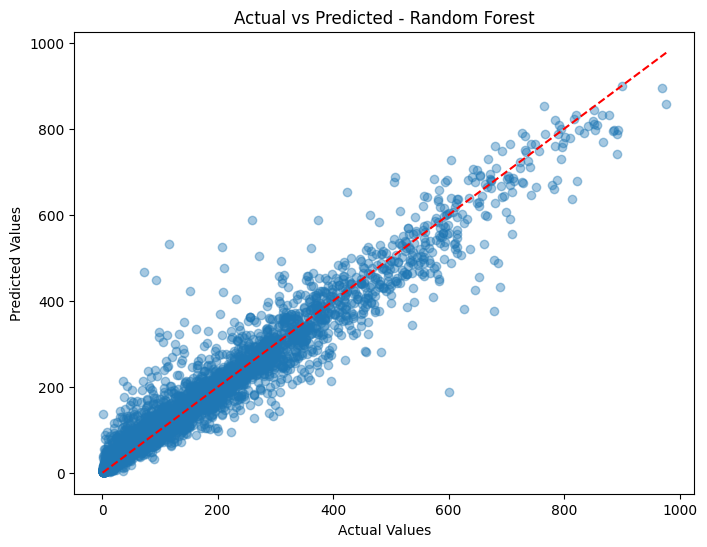

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - " + best_model_name)

plt.show()


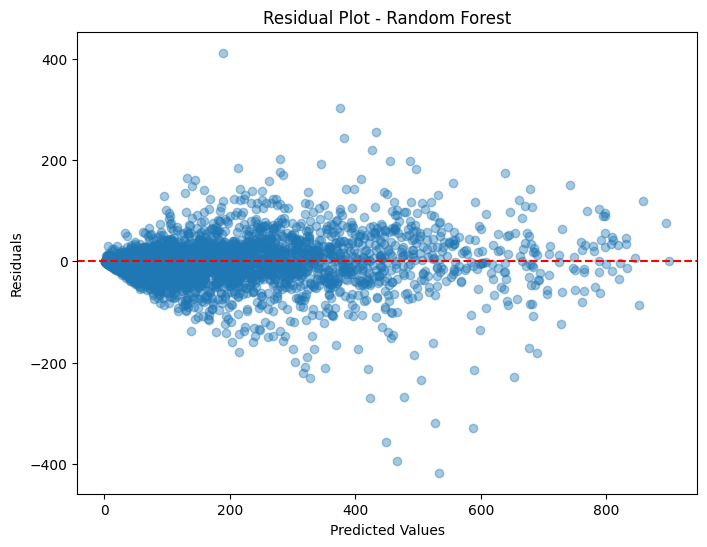

In [ ]:
residuals = y_test - best_predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot - " + best_model_name)

plt.show()


,Feature,Importance
62,cat__is_rush_hour_0,0.121270
1,num__atemp,0.099637
0,num__temp,0.099001
63,cat__is_rush_hour_1,0.088276
2,num__hum,0.070653
9,cat__yr_0,0.044748
42,cat__hr_19,0.038705
57,cat__workingday_1,0.038051
10,cat__yr_1,0.037979
56,cat__workingday_0,0.031761


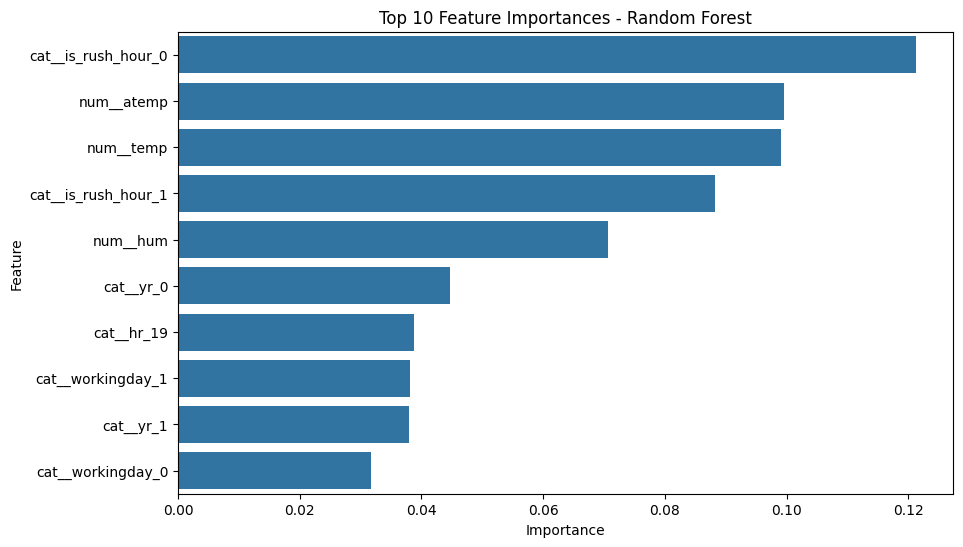

In [ ]:
rf_pipeline = trained_models["Random Forest"]

rf_model = rf_pipeline.named_steps["model"]

feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(10))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()


In [ ]:
best_row = comparison_df.iloc[0]

print(
    f"The best-performing model was {best_row['Model']}, "
    f"with an MAE of {best_row['MAE']:.2f}, "
    f"an RMSE of {best_row['RMSE']:.2f}, "
    f"and an R-squared score of {best_row['R2']:.4f}. "
    "It achieved the lowest RMSE among the four models, "
    "indicating better prediction accuracy on the test dataset. "
    "Its performance suggests that it was effective at "
    "learning the relationships between the input features "
    "and bike rental demand."
)

The best-performing model was Random Forest, with an MAE of 28.63, an RMSE of 46.45, and an R-squared score of 0.9319. It achieved the lowest RMSE among the four models, indicating better prediction accuracy on the test dataset. Its performance suggests that it was effective at learning the relationships between the input features and bike rental demand.


This lab demonstrated how different regression models can be used to predict bike rental demand. I learned how to prepare data, create new features, build preprocessing pipelines, and evaluate models using MAE, RMSE, and R². I also learned that ensemble regression methods, such as Random Forest and Gradient Boosting, can capture complex relationships between features. Comparing different models helps identify the most suitable approach for a prediction problem.